In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Model 2

### State Variables

All three variables are totals for Gilbert Bay (the south arm), not concentrations.

| Symbol | Meaning | Units |
|---|---|---|
| $S(t)$ | Total brine shrimp | shrimp |
| $A(t)$ | Total algae | µg Chl-a |
| $B(t)$ | Total birds | birds |

### Equations

$$
\frac{dS}{dt} = \gamma_S C_A S A - C_S S B - \delta_S S
$$

$$
\frac{dA}{dt} = \beta_A A(1-A/K) - C_A S A
$$

$$
\frac{dB}{dt} = -\delta_B B + \gamma_B C_S S B
$$

### Parameters

| Parameter | Meaning | Value | Units | Brief justification |
|:---:|---|---|---|---|
| $V$ | Lake volume | 2.25 × 10¹³ | L | Volume of the whole lake (22.5 km ^ 3 in liters), from a source that peter got. |
| $\beta_A$ | Algae growth rate | 0.3 | day⁻¹ | A guess. This means that in a sparse environment with only a tiny bit of algae, we could expect it to double every few days, which is realistic. |
| $K$ | Algae carrying capacity (whole lake) | 6 × 10¹⁴ | µg Chl-a | A guess of 50 µg/L × V.  Some studies have used similar numbers. This is the most algae the lake could hold if nothing ate it; growth slows to zero as algae approach this level. |
| $C_A$ | Shrimp feeding rate | 1.7 × 10⁻¹⁵ | 1/(shrimp·day) | A guess.  One shrimp filters about 0.02 L of water per day (Makridis & Vadstein, 1999). Divided by V, this is the tiny fraction of the lake one shrimp clears each day. |
| $C_S$ | Bird feeding rate | 5.8 × 10⁻⁹ | 1/(bird·day) | A guess.  If one grebe searches about 70,000 L of water per day then, dividing by V, this is the fraction of the lake one bird searches. |
| $\gamma_S$ | Shrimp gained per algae eaten | 0.2 | shrimp/µg Chl-a | A guess. This means shrimp must eat about 5 µg of algae (chlorophyll-a) to produce one new shrimp. |
| $\gamma_B$ | Birds gained per shrimp eaten | 5 × 10⁻⁸ | bird/shrimp | A guess. A bird eats ~9 million shrimp per year and raises ~0.5 offspring per year, so it takes ~20 million shrimp to make one new bird. |
| $\delta_S$ | Shrimp natural mortality | 0.03 | day⁻¹ | A guess. This means shrimp live about a month on average (1/0.03 ≈ 33 days), which fits brine shrimp dying off within a season. |
| $\delta_B$ | Bird natural mortality | 0.0003 | day⁻¹ | A guess.  Grebes live around 5 to 10 years.  Choosing an average of 7-8 years = 3000 days ≈ 1 / 0.0003.
| $M$ | Salt mass | 4.10 x 10^12 | kg | Average reported in Mohammed and Tarbotton (2012)
| $N_opt$ | Optimal salinity for shrimp growth | .0825 | kg/L3 | Range of 0.045-0.12 reported in Belovsky et al. (2011). Choosing the average.
| $\sigma$ | Salinity sensitivity | .0575 | kg/L3 | Range of 0.045-0.12 reported in Belovsky et al. (2011). Choosing .0575 so that negative effects start to happen more dramatically at the ends of the range.
| $e_V$ | Rate of volume decrease per year | .0041 | (liter·day) | 1.48 km^3 per year reported in Abbott et al. (2025).

In [6]:
# Parameters:
V = 2.25e13            # lake volume, L
beta_A = 0.3           # algae growth rate, 1/day
K = 50 * V             # algae carrying capacity, µg Chl-a   (50 µg/L × V)
C_A = 0.02 / V         # shrimp feeding rate, 1/(shrimp·day)  (0.02 L/day ÷ V)
C_S = 7e4 / V          # bird feeding rate, 1/(bird·day)      (70,000 L/day ÷ V)
gamma_S = 0.2          # shrimp per µg Chl-a eaten
gamma_B = 5e-8         # birds per shrimp eaten
delta_S = 0.03         # shrimp death rate, 1/day
delta_B = 0.0003       # bird death rate, 1/day

S0 = 0.5 * V           # 0.5 shrimp/L  * V
A0 = 10 * V            # 10 µg/L       * V
B0 = 1.5e6             # birds


# Model 1

Balanced delta_B = 0.0525 per day


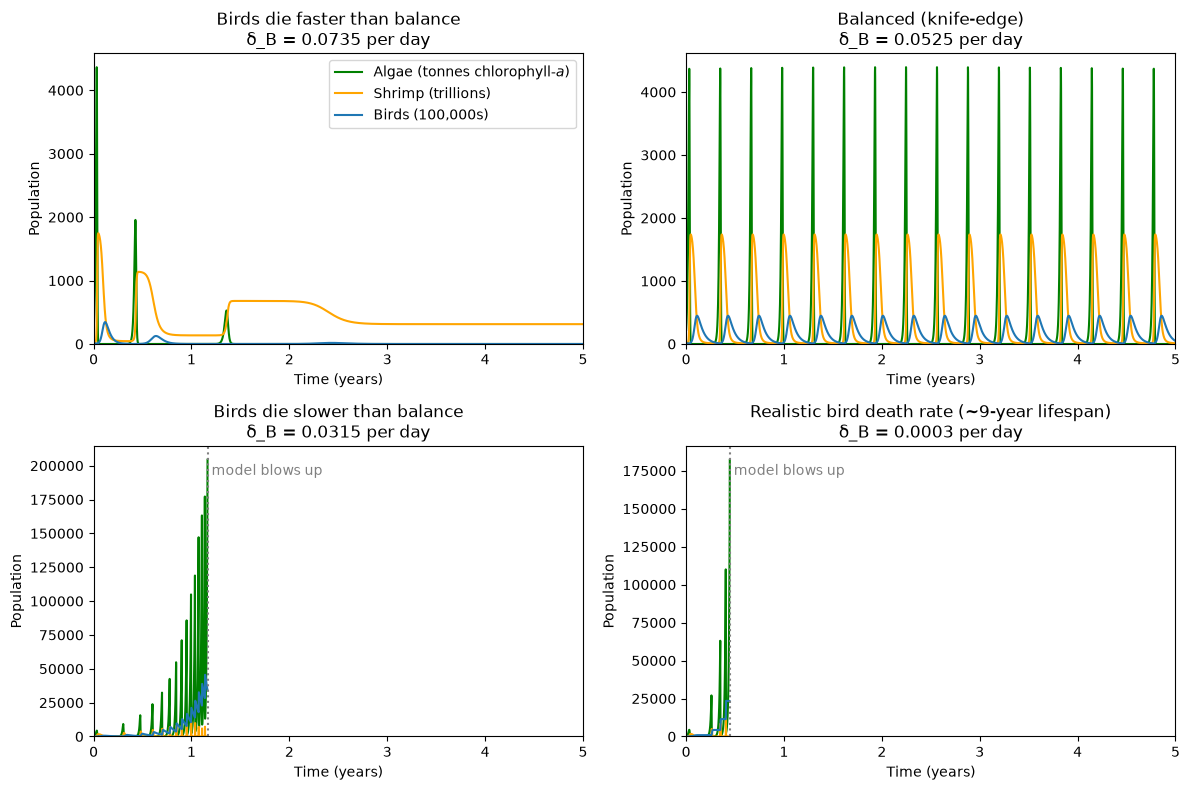

In [7]:

# Balance point: the only bird death rate that allows coexistence
delta_bal = gamma_B * C_S * beta_A / C_A
print(f"Balanced delta_B = {delta_bal:.4f} per day")

# ---------- Units used for solving AND plotting ----------
S_unit = 1e12          # shrimp in trillions
A_unit = 1e12          # algae in tonnes of Chl-a (1 tonne = 1e12 µg)
B_unit = 1e5           # birds in 100,000s

# Starting values in plotting units, computed from the real-unit S0, A0, B0
S0_plot = S0 / S_unit      # 0.5 shrimp/L × V  -> 11.25 trillion shrimp
A0_plot = A0 / A_unit      # 10 µg/L × V       -> 225 tonnes Chl-a
B0_plot = B0 / B_unit      # 1.5 million birds -> 15 (100,000s)

time = 365 * 5

def model(t, y, delta_B):
    # y is in plotting units; convert to real totals for the equations
    S, A, B = y[0] * S_unit, y[1] * A_unit, y[2] * B_unit
    dS = gamma_S * C_A * S * A - C_S * S * B
    dA = beta_A * A - C_A * S * A
    dB = -delta_B * B + gamma_B * C_S * S * B
    return [dS / S_unit, dA / A_unit, dB / B_unit]


def blowup(t, y, delta_B):
    return 1e6 - max(y)      # zero when any variable passes 1e6 (in plot units)
blowup.terminal = True       # stop the run when the model explodes


def run(S0, A0, B0, delta_B, T):
    """Inputs and outputs in plotting units:
    S = trillions of shrimp, A = tonnes of Chl-a, B = millions of birds."""
    t = np.linspace(0, T, 4000)
    sol = solve_ivp(model, (0, T), [S0, A0, B0], args=(delta_B,), t_eval=t,
                    method="LSODA", rtol=1e-9, atol=1e-12, events=blowup)
    S, A, B = sol.y
    return sol.t, S, A, B

cases = [("Birds die faster than balance", 1.4 * delta_bal),
         ("Balanced (knife-edge)", delta_bal),
         ("Birds die slower than balance", 0.6 * delta_bal),
         ("Realistic bird death rate (~9-year lifespan)", 0.0003)]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (name, delta_B) in zip(axes.flat, cases):
    t, S, A, B = run(S0_plot, A0_plot, B0_plot, delta_B, T=time)
    years = t / 365                                  # days -> years
    ax.plot(years, A, label="Algae (tonnes chlorophyll-$a$)", color="green")
    ax.plot(years, S, label="Shrimp (trillions)", color="orange")
    ax.plot(years, B, label="Birds (100,000s)")
    ax.set_title(f"{name}\nδ_B = {delta_B:.4f} per day")
    ax.set_xlim(0, time / 365)
    ax.set_ylim(bottom=0)
    ax.set_xlabel("Time (years)")
    ax.set_ylabel("Population")
    if t[-1] < time:   # the run was stopped because the model blew up
        ax.axvline(years[-1], color="gray", linestyle=":")
        ax.text(years[-1], ax.get_ylim()[1] * 0.9, " model blows up", color="gray")
axes[0, 0].legend()
plt.tight_layout()
plt.savefig("timeseries_2x2.png", dpi=300)
plt.show()

# Model 2

Bird mortality threshold (birds persist below this): 0.0446 per day
Equilibrium: 1.93 trillion shrimp, 1119 tonnes Chl-a, 543 hundred-thousand birds
Jacobian eigenvalues: [-0.2971391+0.j         -0.0005733+0.00710802j -0.0005733-0.00710802j]
Locally stable: True


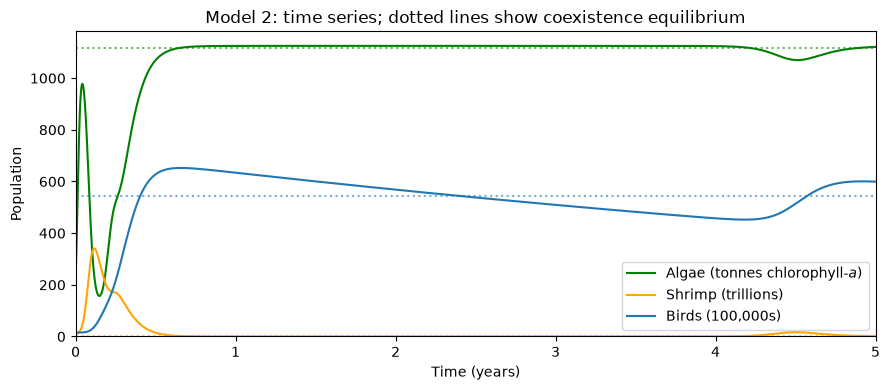

NameError: name 'ICs' is not defined

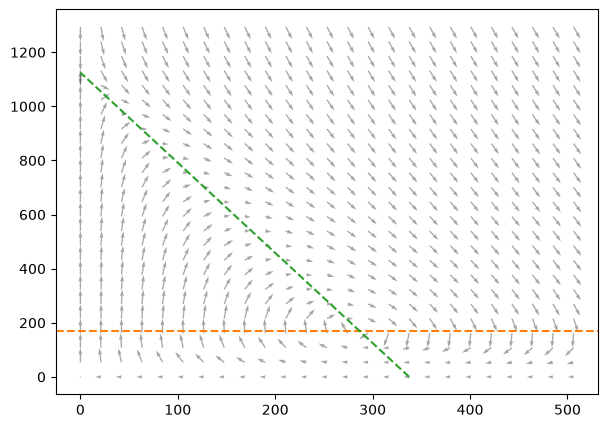

In [ ]:
delta_B = 0.0003    # reset: the 2x2 loop above reuses the name delta_B
y0 = [S0_plot, A0_plot, B0_plot]   # 0.5 shrimp/L, 10 µg/L, 1.5 million birds

# Starting points (shrimp/L, algae µg/L, birds) -> plotting units
IC_densities = [(0.5, 10, 1.5e6), (5, 20, 3e6), (10, 5, 1e7), (20, 30, 5e6)]
ICs = [(s * V / S_unit, a * V / A_unit, b / B_unit) for s, a, b in IC_densities]

def model2(t, y, bird_mortality):
    S, A, B = y[0] * S_unit, y[1] * A_unit, y[2] * B_unit
    dS = gamma_S * C_A * S * A - C_S * S * B - delta_S * S
    dA = beta_A * A * (1 - A / K) - C_A * S * A
    dB = -bird_mortality * B + gamma_B * C_S * S * B
    return [dS / S_unit, dA / A_unit, dB / B_unit]


def run2(initial, T, bird_mortality):
    """initial = [S, A, B] in plotting units. Returns t, S, A, B in plotting units."""
    t = np.linspace(0, T, 4000)
    sol = solve_ivp(model2, (0, T), initial, args=(bird_mortality,), t_eval=t,
                    method="LSODA", rtol=1e-9, atol=1e-12, events=blowup)
    if not sol.success:
        raise RuntimeError(sol.message)
    if np.min(sol.y) < -1e-7:
        raise RuntimeError("Negative numerical populations: inspect solver settings.")
    S, A, B = sol.y
    return sol.t, S, A, B


# Equilibrium and stability (computed in real units)
def equilibrium(bird_mortality):
    S = bird_mortality / (gamma_B * C_S)
    A = K * (1 - C_A * S / beta_A)
    B = (gamma_S * C_A * A - delta_S) / C_S
    return np.array([S, A, B])


def jacobian(state, bird_mortality):
    S, A, B = state
    return np.array([
        [gamma_S * C_A * A - C_S * B - delta_S, gamma_S * C_A * S, -C_S * S],
        [-C_A * A, beta_A * (1 - 2 * A / K) - C_A * S, 0],
        [gamma_B * C_S * B, 0, -bird_mortality + gamma_B * C_S * S],
    ])


units = np.array([S_unit, A_unit, B_unit])
eq = equilibrium(delta_B)                       # real units
eq_plot = eq / units                            # plotting units
threshold = gamma_B * C_S * beta_A / C_A * (1 - delta_S / (gamma_S * C_A * K))

print(f"Bird mortality threshold (birds persist below this): {threshold:.4f} per day")
print(f"Equilibrium: {eq_plot[0]:.2f} trillion shrimp, {eq_plot[1]:.0f} tonnes Chl-a, "
      f"{eq_plot[2]:.0f} hundred-thousand birds")
if np.all(eq > 0):
    eigenvalues = np.linalg.eigvals(jacobian(eq, delta_B))
    print("Jacobian eigenvalues:", eigenvalues)
    print("Locally stable:", np.all(eigenvalues.real < 0))
else:
    print("The equilibrium point is not strictly positive for these parameters.")


# time series plot
t, S, A, B = run2(y0, time, delta_B)
years = t / 365

fig, ax = plt.subplots(figsize=(9, 4))
for values, label, color, eq_value in [(A, "Algae (tonnes chlorophyll-$a$)", "green", eq_plot[1]),
                                       (S, "Shrimp (trillions)", "orange", eq_plot[0]),
                                       (B, "Birds (100,000s)", "tab:blue", eq_plot[2])]:
    ax.plot(years, values, label=label, color=color)
    if np.all(eq > 0):
        ax.axhline(eq_value, color=color, linestyle=":", alpha=0.6)
ax.set(xlabel="Time (years)", ylabel="Population", xlim=(0, time / 365),
       title="Model 2: time series; dotted lines show coexistence equilibrium")
ax.set_ylim(bottom=0)
ax.legend()
fig.tight_layout()
plt.savefig("model2_timeseries.png", dpi=300)
plt.show()


# bird free plot
Smax = 1.5 * beta_A / C_A / S_unit          # trillions of shrimp
Amax = 1.15 * K / A_unit                    # tonnes of Chl-a
SS, AA = np.meshgrid(np.linspace(0, Smax, 25), np.linspace(0, Amax, 25))
S_real, A_real = SS * S_unit, AA * A_unit
dS = S_real * (gamma_S * C_A * A_real - delta_S) / S_unit
dA = A_real * (beta_A * (1 - A_real / K) - C_A * S_real) / A_unit
# Normalize by each axis range to keep direction arrows readable.
speed = np.hypot(dS / Smax, dA / Amax)
scale = np.maximum(speed, 1e-12)

fig, ax = plt.subplots(figsize=(7, 5))
ax.quiver(SS, AA, dS / scale, dA / scale, alpha=0.35, angles="xy")
ax.axhline(delta_S / (gamma_S * C_A) / A_unit, color="tab:orange", linestyle="--",
           label="S'=0 (nonzero)")
a_line = np.linspace(0, K, 200)
ax.plot(beta_A / C_A * (1 - a_line / K) / S_unit, a_line / A_unit, "--",
        color="tab:green", label="A'=0 (nonzero)")
for S_start, A_start, _ in ICs:                    # same starting points, birds removed
    t, S, A, B = run2([S_start, A_start, 0], time, delta_B)
    line, = ax.plot(S, A, linewidth=1.5)
    ax.plot(S_start, A_start, "o", color=line.get_color())
ax.set(xlim=(0, Smax), ylim=(0, Amax), xlabel="Shrimp (trillions)",
       ylabel="Algae (tonnes chlorophyll-$a$)",
       title="Bird-free subsystem: trajectories and nullclines")
ax.legend()
fig.tight_layout()
plt.savefig("model2_phase_plane.png", dpi=300)
plt.show()


# 2x2 plot
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (name, mortality) in zip(axes.flat, cases):
    t, S, A, B = run2(y0, time, mortality)
    years = t / 365
    ax.plot(years, A, label="Algae (tonnes chlorophyll-$a$)", color="green")
    ax.plot(years, S, label="Shrimp (trillions)", color="orange")
    ax.plot(years, B, label="Birds (100,000s)", color="tab:blue")
    ax.set_title(f"{name}\nδ_B = {mortality:.4f} per day")
    ax.set_xlim(0, time / 365)
    ax.set_ylim(bottom=0)
    ax.set_xlabel("Time (years)")
    ax.set_ylabel("Population")
axes[0, 0].legend()
plt.tight_layout()
plt.savefig("model2_timeseries_2x2.png", dpi=300)
plt.show()

# Model 3

Equilibrium: 2.41 trillion shrimp, 1120 tonnes Chl-a, 413 hundred-thousand birds
Jacobian eigenvalues: [-0.29769486+0.j  0.01887243+0.j  0.00131044+0.j]
Locally stable: False


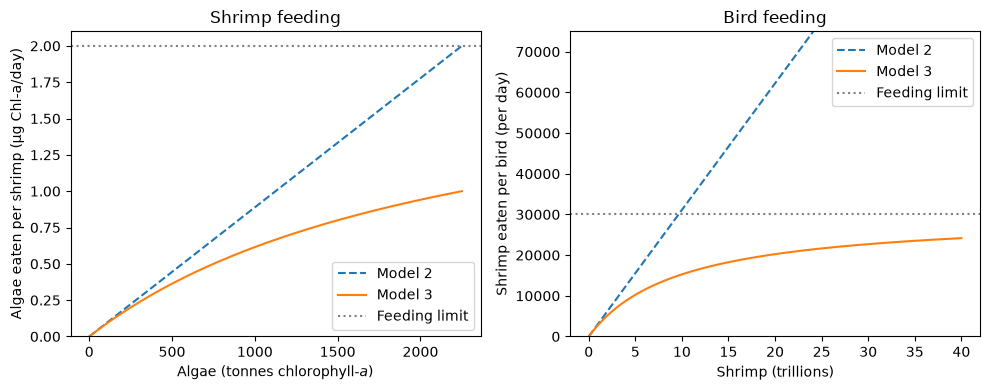

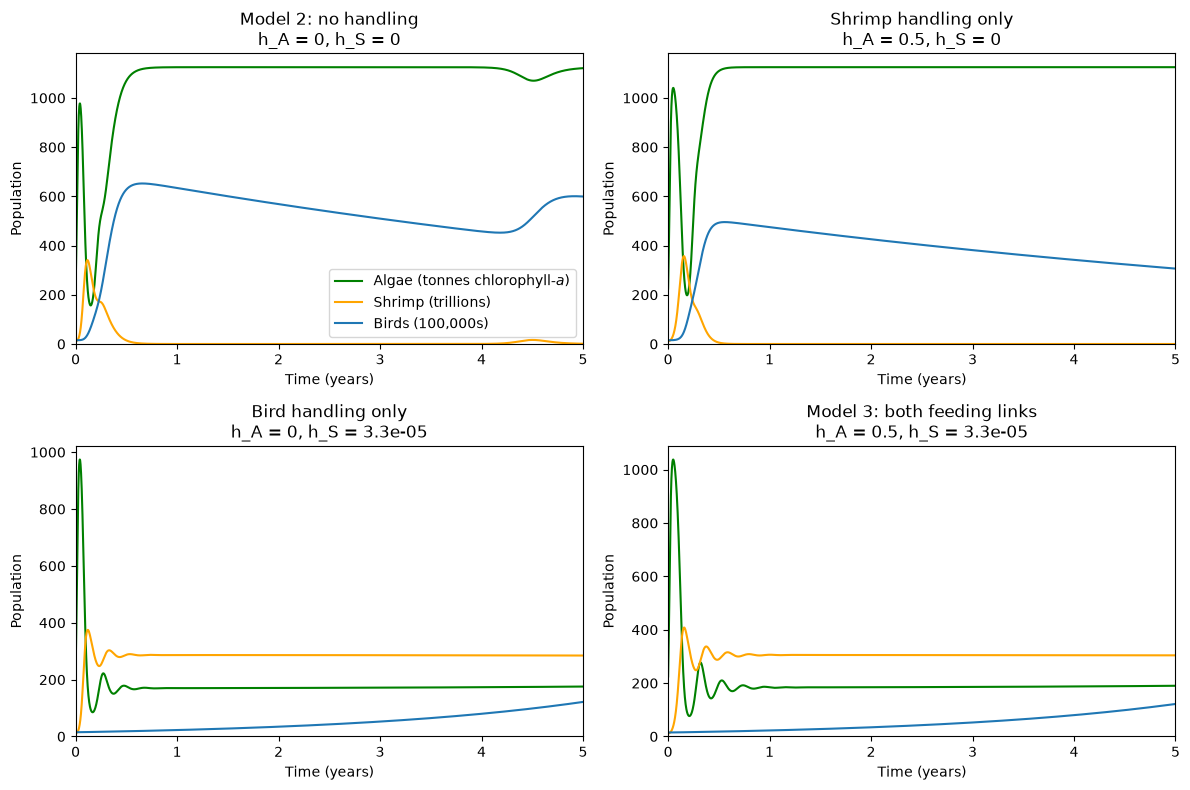

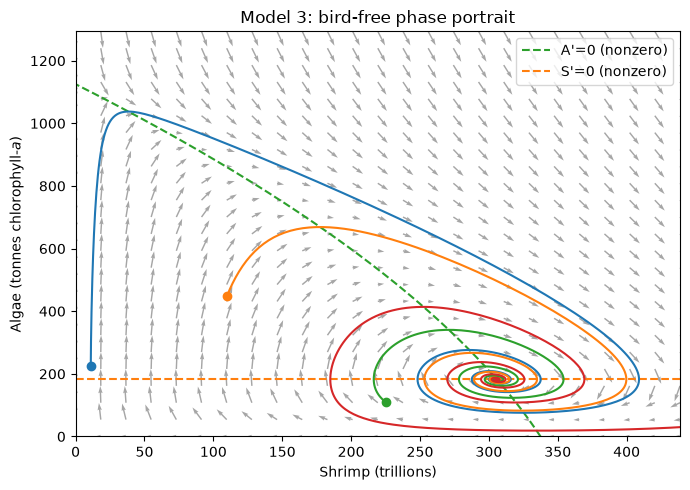

In [ ]:

h_A = 0.5        # day·shrimp/µg Chl-a  -> a shrimp eats at most 1/h_A = 2 µg Chl-a per day (guess)
h_S = 1 / 3e4    # day·bird/shrimp      -> a bird eats at most ~30,000 shrimp per day
                 #                         (grebes eat ~26,500-29,600/day; Conover & Caudell, 2009)


def feeding(food, attack, handling):
    return attack * food / (1 + handling * attack * food)


def model3(t, y, ha, hs, bird_mortality=delta_B):
    # max(..., 0): near-extinctions can make the solver overshoot slightly below zero;
    # a negative shrimp count would make the feeding denominator hit zero.
    S, A, B = (max(y[0], 0) * S_unit, max(y[1], 0) * A_unit, max(y[2], 0) * B_unit)
    algae_eaten = S * feeding(A, C_A, ha)          # µg Chl-a per day, whole lake
    shrimp_eaten = B * feeding(S, C_S, hs)         # shrimp per day, whole lake
    dS = gamma_S * algae_eaten - shrimp_eaten - delta_S * S
    dA = beta_A * A * (1 - A / K) - algae_eaten
    dB = gamma_B * shrimp_eaten - bird_mortality * B
    return [dS / S_unit, dA / A_unit, dB / B_unit]


def run3(initial, T, ha, hs):
    """initial = [S, A, B] in plotting units. Returns t, S, A, B in plotting units."""
    t = np.linspace(0, T, 4000)
    sol = solve_ivp(model3, (0, T), initial, args=(ha, hs), t_eval=t,
                    method="LSODA", rtol=1e-9, atol=1e-12,
                    events=lambda t, y, ha, hs: 1e6 - max(y))
    if not sol.success:
        raise RuntimeError(sol.message)
    if np.min(sol.y) < -1e-7:
        raise RuntimeError("Negative numerical populations: inspect solver settings.")
    S, A, B = sol.y
    return sol.t, S, A, B


# ---------- Equilibrium and stability (real units) ----------
def equilibrium3(ha, hs):
    if gamma_B <= delta_B * hs:
        return []
    S = delta_B / (C_S * (gamma_B - delta_B * hs))
    q = ha * C_A
    # Quadratic in A, rewritten for A in tonnes (a = A / A_unit) so the coefficients are well scaled
    coefficients = [q * A_unit**2, (1 - q * K) * A_unit, K * (C_A * S / beta_A - 1)]
    points = []
    for root in np.roots(coefficients):
        if abs(root.imag) > 1e-8:
            continue
        A = root.real * A_unit
        if not 0 < A < K:
            continue
        B = S * (gamma_S * feeding(A, C_A, ha) - delta_S) / feeding(S, C_S, hs)
        if B > 0:
            points.append(np.array([S, A, B]))
    return points


def jacobian3(state, ha, hs):
    S, A, B = state
    fA = feeding(A, C_A, ha)
    fS = feeding(S, C_S, hs)
    dfA = C_A / (1 + ha * C_A * A)**2
    dfS = C_S / (1 + hs * C_S * S)**2
    return np.array([
        [gamma_S * fA - B * dfS - delta_S, gamma_S * S * dfA, -fS],
        [-fA, beta_A * (1 - 2 * A / K) - S * dfA, 0],
        [gamma_B * B * dfS, 0, gamma_B * fS - delta_B],
    ])


units = np.array([S_unit, A_unit, B_unit])
points = equilibrium3(h_A, h_S)
if not points:
    print("No positive equilibrium for these parameters.")
for eq in points:
    eq_plot = eq / units
    print(f"Equilibrium: {eq_plot[0]:.2f} trillion shrimp, {eq_plot[1]:.0f} tonnes Chl-a, "
          f"{eq_plot[2]:.0f} hundred-thousand birds")
    eigenvalues = np.linalg.eigvals(jacobian3(eq, h_A, h_S))
    print("Jacobian eigenvalues:", eigenvalues)
    print("Locally stable:", np.all(eigenvalues.real < 0))


# feeding curves
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
algae = np.linspace(0, 2 * K / A_unit, 300)           # tonnes Chl-a in the lake (0 to 2K)
shrimp = np.linspace(0, 40, 300)                      # trillions of shrimp (0 to ~1.8 per L)

axes[0].plot(algae, C_A * algae * A_unit, "--", label="Model 2")
axes[0].plot(algae, feeding(algae * A_unit, C_A, h_A), label="Model 3")
axes[0].axhline(1 / h_A, color="gray", linestyle=":", label="Feeding limit")
axes[0].set(xlabel="Algae (tonnes chlorophyll-$a$)",
            ylabel="Algae eaten per shrimp (µg Chl-a/day)",
            title="Shrimp feeding")

axes[1].plot(shrimp, C_S * shrimp * S_unit, "--", label="Model 2")
axes[1].set_ylim(0, 2.5 / h_S)
axes[1].plot(shrimp, feeding(shrimp * S_unit, C_S, h_S), label="Model 3")
axes[1].axhline(1 / h_S, color="gray", linestyle=":", label="Feeding limit")
axes[1].set(xlabel="Shrimp (trillions)",
            ylabel="Shrimp eaten per bird (per day)",
            title="Bird feeding")
axes[0].set_ylim(bottom=0)
for ax in axes:
    ax.legend()
fig.tight_layout()
plt.savefig("model3_feeding_curves.png", dpi=300)
plt.show()


# feeding saturation
trials = [("Model 2: no handling", 0, 0),
          ("Shrimp handling only", h_A, 0),
          ("Bird handling only", 0, h_S),
          ("Model 3: both feeding links", h_A, h_S)]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (title, ha, hs) in zip(axes.flat, trials):
    t, S, A, B = run3(y0, time, ha, hs)
    years = t / 365
    ax.plot(years, A, label="Algae (tonnes chlorophyll-$a$)", color="green")
    ax.plot(years, S, label="Shrimp (trillions)", color="orange")
    ax.plot(years, B, label="Birds (100,000s)", color="tab:blue")
    ax.set_title(f"{title}\nh_A = {ha:.2g}, h_S = {hs:.2g}")
    ax.set_xlim(0, time / 365)
    ax.set_ylim(bottom=0)
    ax.set_xlabel("Time (years)")
    ax.set_ylabel("Population")
axes[0, 0].legend()
plt.tight_layout()
plt.savefig("model3_timeseries_2x2.png", dpi=300)
plt.show()



# bird free portrat
a_line = np.linspace(0, K, 300)                                          # µg Chl-a (real)
s_line = beta_A / C_A * (1 - a_line / K) * (1 + h_A * C_A * a_line)      # shrimp (real)
Smax = 1.3 * np.max(s_line) / S_unit                                     # trillions
Amax = 1.15 * K / A_unit                                                 # tonnes
SS, AA = np.meshgrid(np.linspace(0, Smax, 25), np.linspace(0, Amax, 25))
S_real, A_real = SS * S_unit, AA * A_unit
dS = S_real * (gamma_S * feeding(A_real, C_A, h_A) - delta_S) / S_unit
dA = (beta_A * A_real * (1 - A_real / K) - S_real * feeding(A_real, C_A, h_A)) / A_unit
speed = np.maximum(np.hypot(dS / Smax, dA / Amax), 1e-12)

fig, ax = plt.subplots(figsize=(7, 5))
ax.quiver(SS, AA, dS / speed, dA / speed, alpha=0.35, angles="xy")
ax.plot(s_line / S_unit, a_line / A_unit, "--", color="tab:green", label="A'=0 (nonzero)")
if gamma_S > delta_S * h_A:
    A_star = delta_S / (C_A * (gamma_S - delta_S * h_A)) / A_unit
    if A_star < Amax:
        ax.axhline(A_star, linestyle="--", color="tab:orange", label="S'=0 (nonzero)")
for S_start, A_start, _ in ICs:                      # same starting points, birds removed
    t, S, A, B = run3([S_start, A_start, 0], time, h_A, h_S)
    line, = ax.plot(S, A, linewidth=1.5)
    ax.plot(S_start, A_start, "o", color=line.get_color())
ax.set(xlim=(0, Smax), ylim=(0, Amax), xlabel="Shrimp (trillions)",
       ylabel="Algae (tonnes chlorophyll-$a$)",
       title="Model 3: bird-free phase portrait")
ax.legend()
fig.tight_layout()
plt.savefig("model3_phase_plane.png", dpi=300)
plt.show()